<a href="https://colab.research.google.com/github/arhylsion/rainfall-forecast/blob/main/rainfall_forecast_idn_31c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple Analysis and Prediction Rainfall in 31 Cities Indonesia

This notebook is documentation about the process of prediction monthly rainfall 31 cities of Indonesia using forecast with library **FLAML(AutoML)**.
1. **Library Requirement**
2. **Data Preprocessing & Cleaning**
3. **Train Model**
4. **Result & Visualization**

Please prepare the dataset by downloading the files from the link below:
https://www.kaggle.com/datasets/danielaijdkx/indonesia-daily-weather-31-cities



## Steps 1: Library Requirement

In this steps, need to import library that required and load the dataset (`idn_weather_montly.csv`) to see the base structure row and column of the data

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error
from flaml import AutoML
from flaml.automl.data import add_time_idx_col
import matplotlib.pyplot as plt

### Reading the Dataset

Next, read the `idn_weather_monthly.csv` by using pandas DataFrame and show the first column

In [42]:
df = pd.read_csv('idn_weather_monthly.csv')

print(df.head()) # get the head data
print(df.columns.tolist()) # list of the column

    city province  island       month  temperature_mean  temperature_max_mean  \
0  Ambon   Maluku  Maluku  2000-01-01         26.919355             28.012903   
1  Ambon   Maluku  Maluku  2000-02-01         27.124138             28.251724   
2  Ambon   Maluku  Maluku  2000-03-01         27.112903             28.300000   
3  Ambon   Maluku  Maluku  2000-04-01         27.143333             28.553333   
4  Ambon   Maluku  Maluku  2000-05-01         26.648387             27.638710   

   temperature_min_mean  precipitation_total  rainy_days  days  
0             25.974194                264.9          29    31  
1             25.968966                162.6          25    29  
2             25.822581                126.3          26    31  
3             25.653333                178.5          22    30  
4             25.516129                355.2          29    31  
['city', 'province', 'island', 'month', 'temperature_mean', 'temperature_max_mean', 'temperature_min_mean', 'precipitation_

## Stepes 2: Data Preprocessing & Cleaning

Filter and delete irrelevant collumn and focusing on the actual history of rain

In [43]:
# Clear unused data column
df = df.drop(columns=["island", "temperature_mean", "temperature_max_mean", "temperature_min_mean"], errors='ignore')
df.head()

,city,province,month,precipitation_total,rainy_days,days
0,Ambon,Maluku,2000-01-01,264.9,29,31
1,Ambon,Maluku,2000-02-01,162.6,25,29
2,Ambon,Maluku,2000-03-01,126.3,26,31
3,Ambon,Maluku,2000-04-01,178.5,22,30
4,Ambon,Maluku,2000-05-01,355.2,29,31


### Reorder Column
Reorder column for
Reorder columns to make them easier to read and analyze in a sequential.

In [44]:
# reorder column
col = ["city", "province", "month", "days", "rainy_days", "precipitation_total"]
df = df[col]

df.head()

,city,province,month,days,rainy_days,precipitation_total
0,Ambon,Maluku,2000-01-01,31,29,264.9
1,Ambon,Maluku,2000-02-01,29,25,162.6
2,Ambon,Maluku,2000-03-01,31,26,126.3
3,Ambon,Maluku,2000-04-01,30,22,178.5
4,Ambon,Maluku,2000-05-01,31,29,355.2


## Steps 3: Train Model by Log-Transformation

To address the highly skewed variance in precipitation, apply a log transformation (`log1p`) to the target variable `precipitation_total`. Subsequently, the FLAML model is trained using the LightGBM and XGBoost algorithms.

In [45]:
# create a clean copy
df_log = df_clean.copy()

# do a transformation by using log1p
df_log['precipitation_log'] = np.log1p(df_log['precipitation_total'])

### Data Splitting (Train & Test Split)

Split the data by city, using the last 3 months as the test set (`test_log`) and the preceding historical data as the training set (`train_log`).

In [46]:
test_log = df_log.groupby('city').tail(3).copy()
train_log = df_log.drop(test_log.index)

### Initializing the AutoML Model

Use the FLAML model to train LightGBM (`lgbm`) and XGBoost (`xgboost`) algorithms, with the log-transformed values ​​(`precipitation_log`) as the prediction target.

In [47]:
automl_log = AutoML() # initialization

automl_log.fit(
    dataframe=train_log,
    label='precipitation_log',
    time_col='month',
    group_col='city',
    period=3,
    task='ts_forecast',
    time_budget=120, # 2 min
    estimator_list=['lgbm', 'xgboost'],
    verbose=0
)

INFO:flaml.automl.task.time_series_task:Couldn't import pytorch_lightning, skipping TCN estimator
INFO:flaml.automl.task.time_series_task:Couldn't import orbit, skipping


### Making Predictions and Reverting the Log Scale (Inverse Transform)

Once the predictions are obtained on a log scale,  must revert them to the original millimeter scale using the `expm1` function, while also ensuring that no negative predicted values ​​remain by using `clip`.

In [48]:
pred_log = automl_log.predict(test_log)

test_log['prediction_final'] = np.expm1(pred_log)
test_log['prediction_final'] = np.clip(test_log['prediction_final'], a_min=0, a_max=None)

display(test_log[['city', 'month', 'precipitation_total', 'prediction_final']].head())

,city,month,precipitation_total,prediction_final
318,Ambon,2026-07-01,126.7,124.037942
319,Ambon,2026-08-01,104.2,74.715786
320,Ambon,2026-09-01,80.2,83.411348
640,Balikpapan,2026-07-01,83.1,85.176612
641,Balikpapan,2026-08-01,20.1,180.148772


## Step 4: Result & Visualization

Below is a visualization comparing the rainfall predictions from the FLAML model against actual historical data for several sample cities.

In [49]:
# get 3 sample of the city that will be visualization
sample_city = test_log['city'].unique()[:3]
print("the city to be visualized:", sample_city)

the city to be visualized: ['Ambon' 'Balikpapan' 'Banda Aceh']


### Comparison of Actual vs. Predicted Values

Examining the accuracy of the model’s rainfall trend (increase/decrease) predictions against actual historical data.

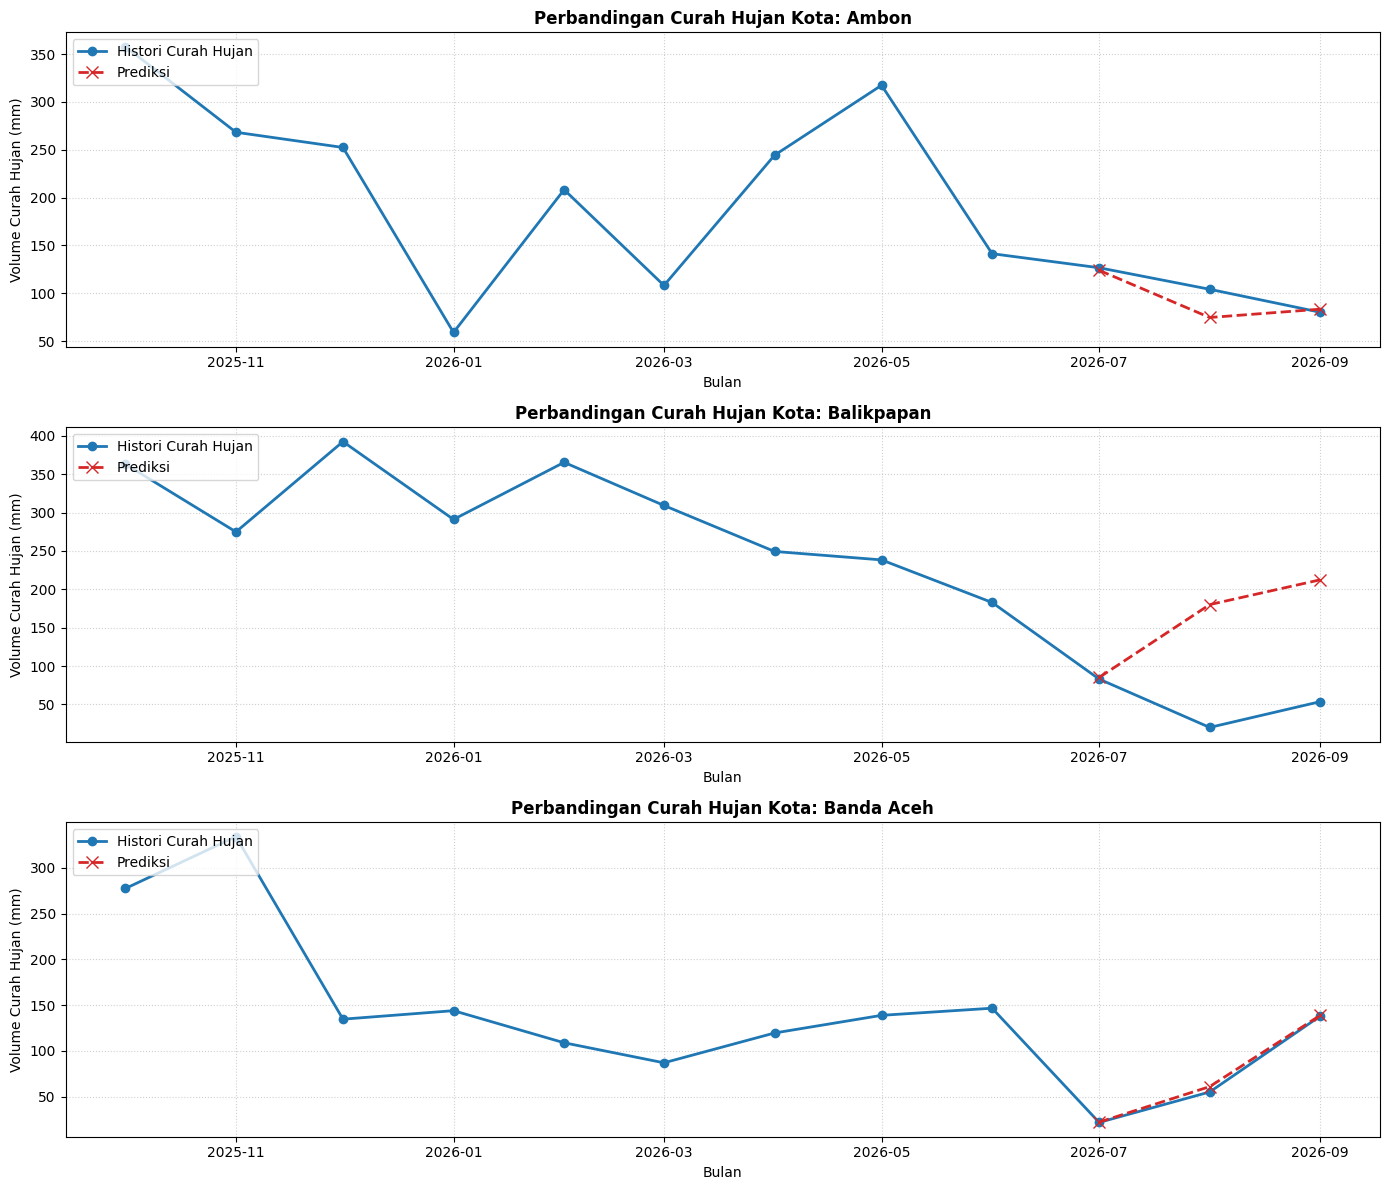

In [50]:
plt.figure(figsize=(14, 4 * len(sample_city)))

for i, k in enumerate(sample_city, 1):
    historis_kota = df_clean[df_clean['city'] == k].tail(12) # get 12 months history rainfall trend
    prediksi_kota = test_log[test_log['city'] == k]

    plt.subplot(len(sample_city), 1, i)

    plt.plot(historis_kota['month'], historis_kota['precipitation_total'],
             label='Histori Curah Hujan', color='#1f77b4', marker='o', linewidth=2)

    plt.plot(prediksi_kota['month'], prediksi_kota['prediction_final'],
             label='Prediksi', color='#d62728', linestyle='--', marker='x', markersize=8, linewidth=2)

    plt.title(f"Perbandingan Curah Hujan Kota: {k}", fontsize=12, fontweight='bold')
    plt.xlabel("Bulan", fontsize=10)
    plt.ylabel("Volume Curah Hujan (mm)", fontsize=10)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()